# Detecção de duplicatas
Limiar 0,85 é o ponto inicial de alta precisão; calibre-o com rótulos humanos.

In [1]:
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from ouvidoria_core import *
base=load_manifestacoes(); textos=[x['texto'] for x in base]; ids=[x['id'] for x in base]
E=embed_texts(textos, MODEL_OPTIONS['Multilíngue MiniLM (recomendado)']); S=cosine_matrix(E)

C:\Users\Caio Araujo\AppData\Roaming\Python\Python38\site-packages\sentence_transformers\cross_encoder\CrossEncoder.py:13: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm, trange


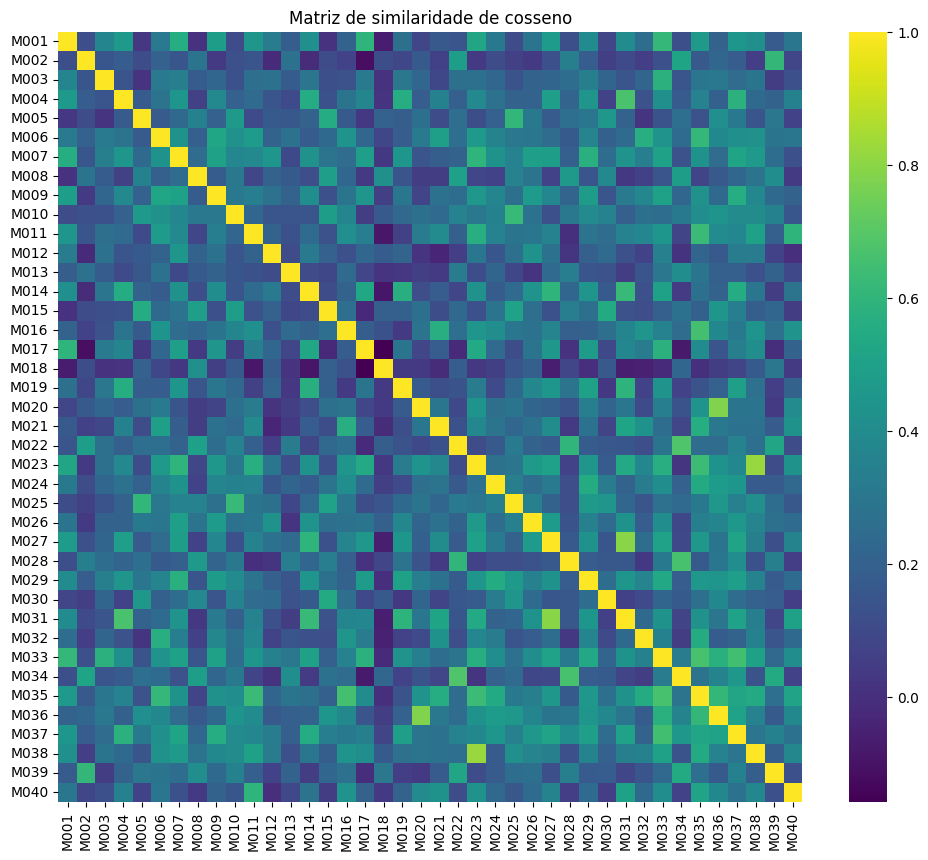

,id_1,id_2,similaridade


In [ ]:
plt.figure(figsize=(12,10)); sns.heatmap(S, cmap='viridis', xticklabels=ids, yticklabels=ids); plt.title('Matriz de similaridade de cosseno'); plt.show()
pares=detectar_duplicatas(textos, .85, MODEL_OPTIONS['Multilíngue MiniLM (recomendado)'])
pd.DataFrame([(ids[i],ids[j],round(s,3)) for i,j,s in pares], columns=['id_1','id_2','similaridade'])

## Análise de falsos positivos e falsos negativos
Os pares abaixo foram anotados manualmente como o mesmo problema, com formulações diferentes. Eles são a referência para avaliar a triagem automática.

In [ ]:
# Referência de duplicatas semânticas do corpus
duplicatas_reais = {tuple(sorted(p)) for p in [('M001','M017'), ('M003','M033'), ('M006','M032'), ('M008','M022'), ('M008','M034'), ('M011','M035'), ('M016','M040'), ('M020','M036'), ('M023','M038'), ('M027','M031'), ('M002','M039'), ('M004','M037')]}
previstos = {tuple(sorted((ids[i], ids[j]))) for i,j,_ in pares}
vp, fp, fn = previstos & duplicatas_reais, previstos - duplicatas_reais, duplicatas_reais - previstos
precisao = len(vp) / len(previstos) if previstos else 0
revocacao = len(vp) / len(duplicatas_reais)
pd.DataFrame({'métrica':['Verdadeiros positivos','Falsos positivos','Falsos negativos','Precisão','Revocação'], 'valor':[len(vp),len(fp),len(fn),f'{precisao:.1%}',f'{revocacao:.1%}']})

,métrica,valor
0,Verdadeiros positivos,0
1,Falsos positivos,0
2,Falsos negativos,12
3,Precisão,0.0%
4,Revocação,0.0%


In [ ]:
def tabela_pares(conjunto):
    return pd.DataFrame([{'par':f'{a} × {b}', 'similaridade':round(float(S[ids.index(a), ids.index(b)]),3)} for a,b in sorted(conjunto)])
print('Falsos positivos:'); display(tabela_pares(fp))
print('Falsos negativos:'); display(tabela_pares(fn))

Falsos positivos:


""


Falsos negativos:


,par,similaridade
0,M001 × M017,0.593
1,M002 × M039,0.610
2,M003 × M033,0.581
3,M004 × M037,0.580
4,M006 × M032,0.569
5,M008 × M022,0.494
6,M008 × M034,0.483
7,M011 × M035,0.625
8,M016 × M040,0.437
9,M020 × M036,0.779


**Conclusão sobre o limiar.** O valor 0,85 é mantido como padrão da função porque favorece precisão: só sinaliza casos quase idênticos. Porém, neste corpus ele é conservador demais para paráfrases cidadãs e gera falsos negativos. A análise dos scores dos falsos negativos permite calibrar um segundo limiar operacional (por exemplo, entre 0,30 e 0,50) para uma fila de revisão humana. Essa redução aumenta a revocação, mas exige inspecionar falsos positivos, pois textos da mesma categoria podem ser relacionados sem serem duplicados.